## Bagging with decision trees on the Wine data

In [2]:
import pandas as pd

#df_wine = pd.read_csv('https://archive.ics.uci.edu/ml/'
#                      'machine-learning-databases/wine/wine.data',
#                      header=None)
# .. or:
df_wine = pd.read_csv('https://raw.githubusercontent.com/rasbt/'
                      'python-machine-learning-book-3rd-edition/master/ch07/wine.data',
                      header=None)

df_wine.columns = ['Class label', 'Alcohol', 'Malic acid', 'Ash',
                   'Alcalinity of ash', 'Magnesium', 'Total phenols',
                   'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins',
                   'Color intensity', 'Hue', 'OD280/OD315 of diluted wines',
                   'Proline']

# drop 1 class
df_wine = df_wine[df_wine['Class label'] != 1]

y = df_wine['Class label'].values
X = df_wine[['Alcohol', 'OD280/OD315 of diluted wines']].values  # Selection of only two features
# X = df_wine[['Alcohol', 'Malic acid', 'Ash',
#                    'Alcalinity of ash', 'Magnesium', 'Total phenols',
#                    'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins',
#                    'Color intensity', 'Hue', 'OD280/OD315 of diluted wines',
#                    'Proline']].values
df_wine.head()

,Class label,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
59,2,12.37,0.94,1.36,10.6,88,1.98,0.57,0.28,0.42,1.95,1.05,1.82,520
60,2,12.33,1.10,2.28,16.0,101,2.05,1.09,0.63,0.41,3.27,1.25,1.67,680
61,2,12.64,1.36,2.02,16.8,100,2.02,1.41,0.53,0.62,5.75,0.98,1.59,450
62,2,13.67,1.25,1.92,18.0,94,2.10,1.79,0.32,0.73,3.80,1.23,2.46,630
63,2,12.37,1.13,2.16,19.0,87,3.50,3.10,0.19,1.87,4.45,1.22,2.87,420


In [3]:
X

array([[12.37,  1.82],
       [12.33,  1.67],
       [12.64,  1.59],
       [13.67,  2.46],
       [12.37,  2.87],
       [12.17,  2.23],
       [12.37,  2.3 ],
       [13.11,  3.18],
       [12.37,  3.48],
       [13.34,  1.93],
       [12.21,  3.07],
       [12.29,  1.82],
       [13.86,  3.16],
       [13.49,  2.78],
       [12.99,  3.5 ],
       [11.96,  3.13],
       [11.66,  2.14],
       [13.03,  2.48],
       [11.84,  2.52],
       [12.33,  2.31],
       [12.7 ,  3.13],
       [12.  ,  3.12],
       [12.72,  3.14],
       [12.08,  2.72],
       [13.05,  2.01],
       [11.84,  3.08],
       [12.67,  3.16],
       [12.16,  2.26],
       [11.65,  3.21],
       [11.64,  2.75],
       [12.08,  3.21],
       [12.08,  2.27],
       [12.  ,  2.65],
       [12.69,  2.06],
       [12.29,  3.3 ],
       [11.62,  2.96],
       [12.47,  2.63],
       [11.81,  2.26],
       [12.29,  2.74],
       [12.37,  2.77],
       [12.29,  2.83],
       [12.08,  2.96],
       [12.6 ,  2.77],
       [12.

In [4]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

# Encode the class labels
le = LabelEncoder()
y = le.fit_transform(y)

# X, y = make_circles(n_samples=100, random_state=123) # Extra dataset for visualisation

[X_train, X_test, y_train, y_test] =\
                             train_test_split(X, y,
                             test_size=0.2,
                             random_state=1,
                             stratify=y)
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1])

### Prepare the classifiers for "Bagging"
A BaggingClassifier algorithm is already implemented in scikit-learn, which can be imported from the ensemble submodule. Below, we will use an __unpruned decision tree as the base classifier__ and create an ensemble of __500 decision trees__ fit on different bootstrap samples of the training dataset:

In [5]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree     import DecisionTreeClassifier


# Base estimator: A decision tree (can be any classifier)
tree = DecisionTreeClassifier(
    criterion='entropy',   # Use entropy (information gain) for splits
    max_depth=None,        # Allow trees to grow as deep as needed (may overfit)
    random_state=1         # For reproducibility
)

# Bagging ensemble using the decision tree as the base model
bag = BaggingClassifier(
    estimator=tree,              # Base estimator for bagging (use 'estimator' in sklearn ≥1.2)
    n_estimators=500,            # Number of bootstrap models (trees) to train
    max_samples=1.0,             # Each tree gets 100% of the training data (with replacement)
    max_features=1.0,            # Each tree considers 100% of the features when splitting
    bootstrap=True,              # Bootstrap sampling (with replacement) of training data
    bootstrap_features=False,    # Do not bootstrap features (use all features per tree)
    n_jobs=1,                    # Number of parallel jobs (-1 = use all CPUs)
    random_state=1               # Reproducible randomness
)

### Fit the classifiers and make predictions for the training- and testdata

In [6]:
from sklearn.metrics import accuracy_score

# Fit a single tree
tree = tree.fit(X_train, y_train)

# Predict with the tree-model
y_train_pred = tree.predict(X_train)
y_test_pred  = tree.predict(X_test)

print(tree.get_params())
print("")

{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 1, 'splitter': 'best'}



In [7]:
tree_train = accuracy_score(y_train, y_train_pred)
tree_test  = accuracy_score(y_test, y_test_pred)
print('Single decision tree train/test accuracies: %.3f/%.3f'
      % (tree_train, tree_test))

# Fit the 500 bootstrapped trees
bag = bag.fit(X_train, y_train)

# Predict with the bag-model
y_train_pred = bag.predict(X_train)
y_test_pred  = bag.predict(X_test)

bag_train = accuracy_score(y_train, y_train_pred)
bag_test  = accuracy_score(y_test, y_test_pred)
print('Bagging train/test accuracies: %.3f/%.3f'
      % (bag_train, bag_test))

Single decision tree train/test accuracies: 1.000/0.833
Bagging train/test accuracies: 1.000/0.917


Although the training accuracies of the decision tree and bagging classifier are similar
on the training set (both 100 percent), we can see that the bagging classifier has a
slightly better generalization performance, as estimated on the test set.

### Visualize the decision regions for the tree and for the bag classifier:

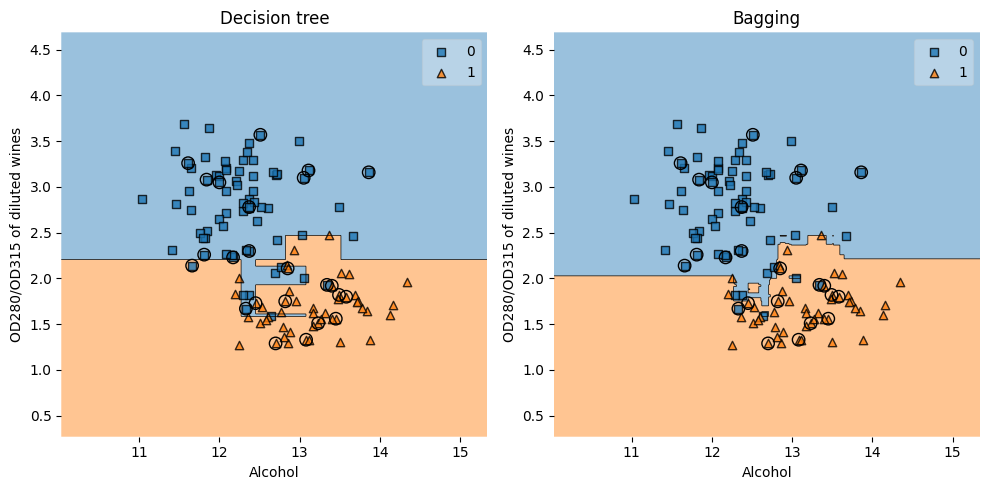

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions

[f, axarr] = plt.subplots(nrows=1, ncols=2,
                        sharex='col',
                        sharey='row',
                        figsize=(10, 5))
for i, (clf, header) in enumerate(zip([tree, bag], ['Decision tree','Bagging'])):
    plot_decision_regions(X, y, clf = clf, ax = axarr[i],
                          X_highlight = X_test, scatter_highlight_kwargs={'c':'none', 'facecolors':'none'}) # Highlight test data with circles
    axarr[i].set_xlabel('Alcohol')
    axarr[i].set_ylabel('OD280/OD315 of diluted wines')
    axarr[i].set_title(header)
    plt.tight_layout()
plt.show()

In general, bagging an overfitted classifier helps overcome variance, while biased classifiers will still be biased after bagging.

Back to presentation

## Applying AdaBoost with scikit-learn
We consider the same classification problem based on the Wine dataset

### Define the AdaBoost classifier:

In [9]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

# Base weak learner: decision stump (shallow tree)
tree = DecisionTreeClassifier(
    criterion='entropy',   # Use information gain
    max_depth=1,           # Tree stump = only one split
    random_state=1         # Reproducibility
)

# AdaBoost ensemble
ada = AdaBoostClassifier(
    estimator=tree,         # Use 'estimator' (not 'base_estimator') for scikit-learn >= 1.2
    n_estimators=500,       # Number of boosting rounds (iterations)
    learning_rate=1.0,      # Controls the contribution of each weak learner
                            # Lower = more conservative model, slower learning
    random_state=1          # Reproducibility
)


### Fit and test tree stump and the AdaBoost classifier

In [10]:
# Fit and test the tree stump
tree         = tree.fit(X_train, y_train)
y_train_pred = tree.predict(X_train)
y_test_pred  = tree.predict(X_test)

tree_train   = accuracy_score(y_train, y_train_pred)
tree_test    = accuracy_score(y_test, y_test_pred)
print('Decision tree train/test accuracies %.3f/%.3f' % (tree_train, tree_test))

# Fit and test AdaBoost
ada          = ada.fit(X_train, y_train)
y_train_pred = ada.predict(X_train)
y_test_pred  = ada.predict(X_test)

ada_train    = accuracy_score(y_train, y_train_pred)
ada_test     = accuracy_score(y_test, y_test_pred)
print('AdaBoost train/test accuracies %.3f/%.3f'  % (ada_train, ada_test))

Decision tree train/test accuracies 0.916/0.875
AdaBoost train/test accuracies 1.000/0.917


### Visualization of the decision regions

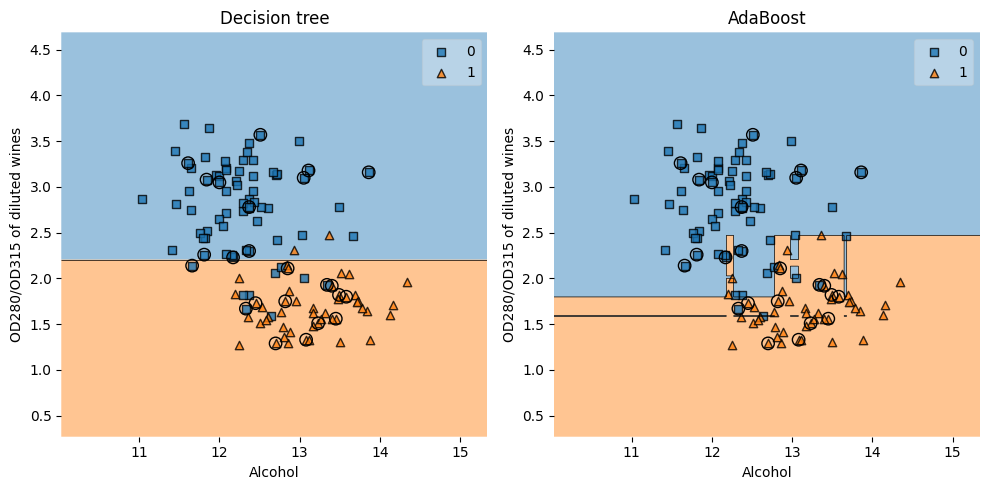

In [11]:
[f, axarr] = plt.subplots(nrows=1, ncols=2,
                        sharex='col',
                        sharey='row',
                        figsize=(10, 5))
for i, (clf, header) in enumerate(zip([tree, ada], ['Decision tree','AdaBoost'])):
    plot_decision_regions(X, y, clf = clf, ax = axarr[i],
                          X_highlight = X_test) # Highlight test data with circles
    axarr[i].set_xlabel('Alcohol')
    axarr[i].set_ylabel('OD280/OD315 of diluted wines')
    axarr[i].set_title(header)
    plt.tight_layout()
plt.show()

By looking at the decision regions, we see that __the decision boundary of the AdaBoost model is substantially more complex than the decision boundary of the decision stump__. In addition, we __note that the AdaBoost quite separates the feature space very similarly to the bagging classifier__ that we trained above.